# Traditional detector: LoG blob detection

In [2]:
# Set up imports and load validation and test data.
import sys
import time
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path("src").resolve()))
from common import load_split, show_plt, calc_iou, calc_avg_precision
from traditional.detector import detect_birds

val_samples = load_split("val")
test_samples = load_split("test")

val_GT_boxes = []
for sample in val_samples:
    val_GT_boxes.append(sample["boxes"])

test_GT_boxes = []
for sample in test_samples:
    test_GT_boxes.append(sample["boxes"])

In [3]:
# Verify AP calculations using ground truth boxes for perfect predictions.

perfect_preds = []
for gt_boxes in val_GT_boxes:
    perfect_preds.append((gt_boxes, np.ones(len(gt_boxes))))

map_on_gt = calc_avg_precision(perfect_preds, val_GT_boxes)
print(f"Check: using ground truth boxes as predictions gives mAP {map_on_gt:.2f} (should be 1.0)")

Check: using ground truth boxes as predictions gives mAP 1.00 (should be 1.0)


In [4]:
# Evaluate detection accuracy and processing time on the validation set.
start_time = time.perf_counter()
val_predictions = []
for sample in val_samples:
    val_predictions.append(detect_birds(sample["path"]))

print(f"Validation mAP@0.5: {calc_avg_precision(val_predictions, val_GT_boxes):.4f}")
print(f"Time per image: {(time.perf_counter() - start_time) / len(val_samples):.3f} s")

Validation mAP@0.5: 0.0023
Time per image: 0.488 s


In [5]:
# Checks prediction counts and recall at IoU 0.5
image_mean_pred = np.mean([len(boxes) for boxes, _ in val_predictions])
image_mean_gt = np.mean([len(boxes) for boxes in val_GT_boxes])

matches = 0
for (pred_boxes, _), gt_boxes in zip(val_predictions, val_GT_boxes):
    for gt_box in gt_boxes:
        if len(pred_boxes) and calc_iou(gt_box, pred_boxes).max() >= 0.5:
            matches += 1

total_gt = 0
for boxes in val_GT_boxes:
    total_gt += len(boxes)

print(f"Mean predictions per image: {image_mean_pred:.1f} (ground truth: {image_mean_gt:.1f})")
print(f"Recall at IoU 0.5: {matches / total_gt:.3f}")

Mean predictions per image: 197.1 (ground truth: 6.3)
Recall at IoU 0.5: 0.154


In [6]:
# Evaluate detection accuracy and processing time on the test set.
start_time = time.perf_counter()
test_predictions = []
for sample in test_samples:
    test_predictions.append(detect_birds(sample["path"]))

print(f"Test mAP@0.5: {calc_avg_precision(test_predictions, test_GT_boxes):.4f}")
print(f"Time per image: {(time.perf_counter() - start_time) / len(test_samples):.3f} s")

Test mAP@0.5: 0.0077
Time per image: 0.484 s


## Final results LoG

Configuration: SIGMAS = geomspace(8, 40, 6), THRESHOLD = 0.03, NMS IoU = 0.3.

| Split | mAP@0.5 | Inference time per image |
|---|---|---|
| Validation (291 images) | 0.0023 | 0.488 s |
| Test (240 images) | 0.0077 | 0.484 s |

Training time: not applicable as LoG has no training step.

Good examples F1 scores: [0.011, 0.011, 0.012]
Bad examples F1 scores: [0.0, 0.0, 0.0]


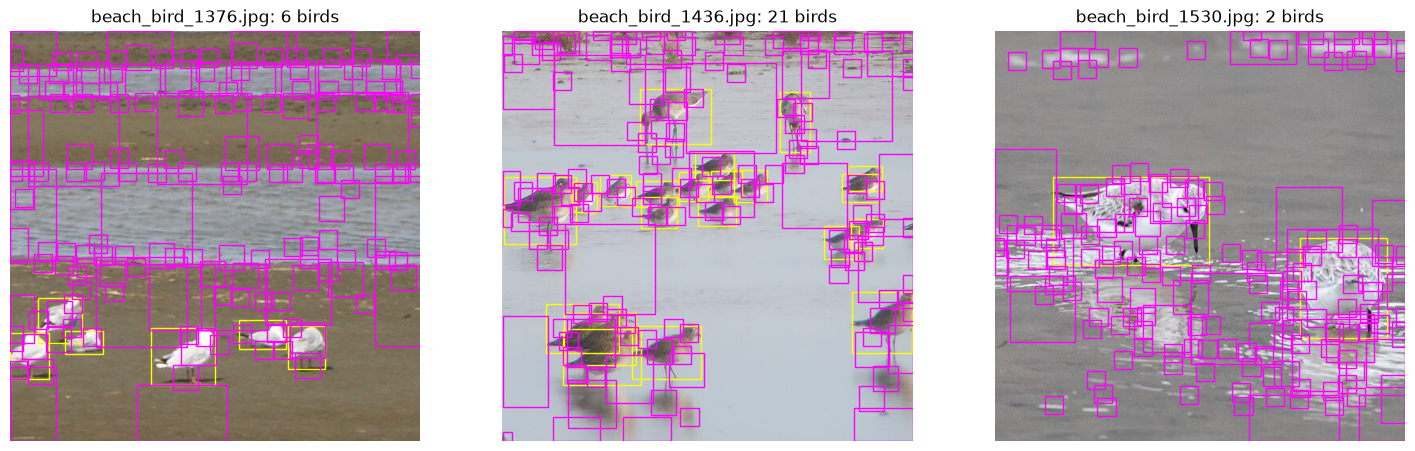

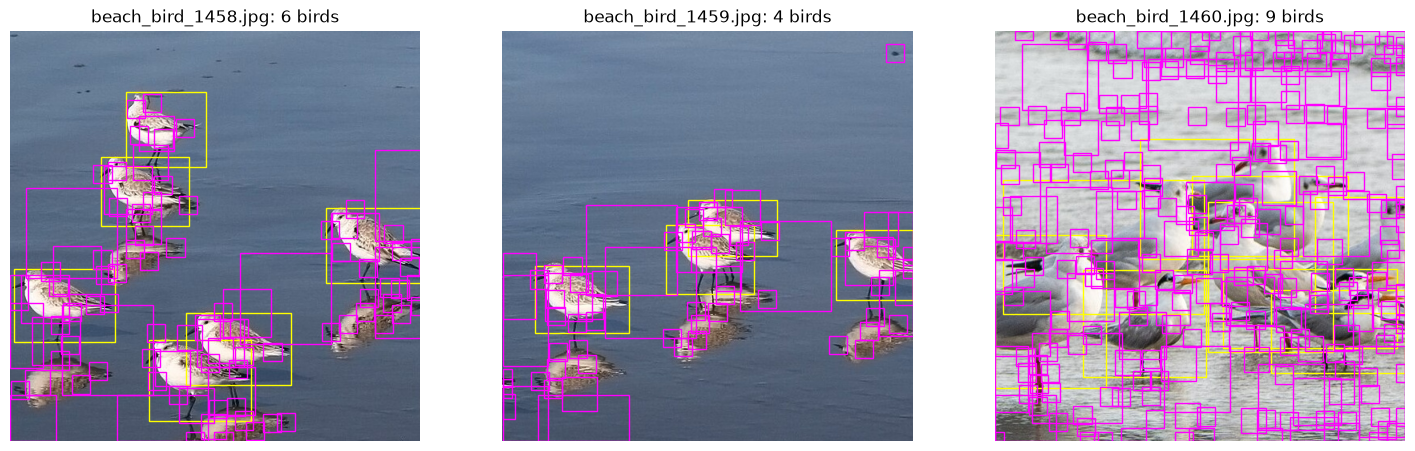

In [10]:
# Calculate F1 for each validation image.
f1_scores = []

for img_idx, ((pred_boxes, pred_scores), gt_boxes) in enumerate(zip(val_predictions, val_GT_boxes)):
    matched_gt = np.zeros(len(gt_boxes), dtype=bool)
    matches = 0

    # Highest confidence predictions claim GT boxes first
    for pred_idx in np.argsort(-pred_scores):
        if len(gt_boxes) == 0:
            break

        iou_scores = calc_iou(pred_boxes[pred_idx], gt_boxes)
        iou_scores[matched_gt] = 0
        best_match_idx = int(iou_scores.argmax())

        if iou_scores[best_match_idx] >= 0.5:
            matched_gt[best_match_idx] = True
            matches += 1

    false_pos = len(pred_boxes) - matches
    false_neg = len(gt_boxes) - matches
    denom = 2 * matches + false_pos + false_neg
    f1 = 1.0 if denom == 0 else 2 * matches / denom
    f1_scores.append((f1, img_idx))

f1_scores.sort()

# Take 3 good and 3 bad examples from around the 80th and 20th percentiles so that we aren't using extreme outliers
good_pos = int(0.8 * len(f1_scores))
bad_pos = int(0.2 * len(f1_scores))

best_img_idxs = []
for _, img_idx in f1_scores[good_pos - 1:good_pos + 2]:
    best_img_idxs.append(img_idx)

worst_img_idxs = []
for _, img_idx in f1_scores[bad_pos - 1:bad_pos + 2]:
    worst_img_idxs.append(img_idx)

print("Good examples F1 scores:", [round(f1_scores[s][0], 3) for s in range(good_pos - 1, good_pos + 2)])
print("Bad examples F1 scores:", [round(f1_scores[s][0], 3) for s in range(bad_pos - 1, bad_pos + 2)])

# Retrieve the corresponding samples and predictions.
best_samples = []
best_predictions = []
for img_idx in best_img_idxs:
    best_samples.append(val_samples[img_idx])
    best_predictions.append(val_predictions[img_idx])

worst_samples = []
worst_predictions = []
for img_idx in worst_img_idxs:
    worst_samples.append(val_samples[img_idx])
    worst_predictions.append(val_predictions[img_idx])

show_plt(best_samples, best_predictions, 3)
show_plt(worst_samples, worst_predictions, 3)